# 01_Preprocessing.ipynb

## Multi Model Medical Image Analysis for Pancreatic Disease

### Objective
This notebook performs preprocessing of pancreas CT scans by:
- Loading NIfTI CT images
- Normalizing intensity values
- Resampling to uniform voxel spacing
- Cropping the pancreas region
- Saving processed images and labels as NumPy (.npy) files

In [1]:
import os
import glob
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

from monai.transforms import (
    Compose,
    LoadImage,
    EnsureChannelFirst,
    Orientation,
    Spacing,
    ScaleIntensity,
    CropForeground
)

In [2]:
# Dataset folders
images_dir = "../Task07_Pancreas/imagesTr"
labels_dir = "../Task07_Pancreas/labelsTr"

# Output folders
processed_images = "../processed/images"
processed_labels = "../processed/labels"

os.makedirs(processed_images, exist_ok=True)
os.makedirs(processed_labels, exist_ok=True)

In [3]:
image_files = sorted(
    glob.glob(os.path.join(images_dir, "*.nii"))
)

label_files = sorted(
    glob.glob(os.path.join(labels_dir, "*.nii"))
)

print("Number of Images :", len(image_files))
print("Number of Labels :", len(label_files))

print("\nSample Image:")
print(image_files[0])

print("\nSample Label:")
print(label_files[0])

Number of Images : 281
Number of Labels : 281

Sample Image:
../Task07_Pancreas/imagesTr\pancreas_001.nii

Sample Label:
../Task07_Pancreas/labelsTr\pancreas_001.nii


In [4]:
image_preprocess = Compose([

    LoadImage(image_only=True),

    EnsureChannelFirst(),

    Orientation(axcodes="RAS"),

    Spacing(
        pixdim=(1.5,1.5,2.0),
        mode="bilinear"
    ),

    ScaleIntensity(),

    CropForeground()
])

c:\Pancreas_\.venv\Lib\site-packages\monai\utils\deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.array Orientation.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


In [5]:
label_preprocess = Compose([

    LoadImage(image_only=True),

    EnsureChannelFirst(),

    Orientation(axcodes="RAS"),

    Spacing(
        pixdim=(1.5,1.5,2.0),
        mode="nearest"
    ),

    CropForeground()
])

In [6]:
sample_image = image_preprocess(image_files[0])
sample_label = label_preprocess(label_files[0])

print("Image Shape :", sample_image.shape)
print("Label Shape :", sample_label.shape)

Image Shape : torch.Size([1, 221, 221, 137])
Label Shape : torch.Size([1, 67, 37, 36])


Image Shape : (221, 221, 137)
Label Shape : (67, 37, 36)


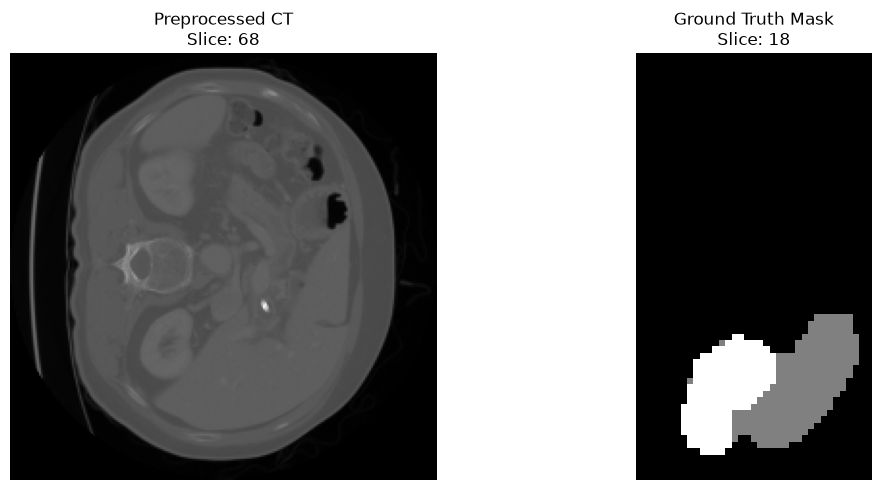

In [7]:
import matplotlib.pyplot as plt

# Convert MetaTensor to NumPy
image = sample_image.numpy()[0]
label = sample_label.numpy()[0]

print("Image Shape :", image.shape)
print("Label Shape :", label.shape)

# Use the middle slice of each volume separately
image_slice = image.shape[2] // 2
label_slice = label.shape[2] // 2

plt.figure(figsize=(12, 5))

# Display CT image
plt.subplot(1, 2, 1)
plt.imshow(image[:, :, image_slice], cmap="gray")
plt.title(f"Preprocessed CT\nSlice: {image_slice}")
plt.axis("off")

# Display label
plt.subplot(1, 2, 2)
plt.imshow(label[:, :, label_slice], cmap="gray")
plt.title(f"Ground Truth Mask\nSlice: {label_slice}")
plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
np.save(
    os.path.join(processed_images, "sample.npy"),
    sample_image.numpy()
)

np.save(
    os.path.join(processed_labels, "sample.npy"),
    sample_label.numpy()
)

print("Sample saved successfully.")

Sample saved successfully.


In [9]:
for image_path in image_files:

    image = image_preprocess(image_path)

    filename = Path(image_path).stem + ".npy"

    np.save(
        os.path.join(processed_images, filename),
        image.numpy()
    )

print("All CT images processed.")

All CT images processed.


In [10]:
for label_path in label_files:

    label = label_preprocess(label_path)

    filename = Path(label_path).stem + ".npy"

    np.save(
        os.path.join(processed_labels, filename),
        label.numpy()
    )

print("All labels processed.")

All labels processed.


In [11]:
processed_image_files = sorted(
    glob.glob("../processed/images/*.npy")
)

processed_label_files = sorted(
    glob.glob("../processed/labels/*.npy")
)

print("Processed Images :", len(processed_image_files))
print("Processed Labels :", len(processed_label_files))

Processed Images : 282
Processed Labels : 282


## Preprocessing Completed

Loaded NIfTI CT images

Normalized image intensities

Resampled voxel spacing

 Cropped pancreas region

Saved processed images and labels as `.npy`

The processed data is now ready for the segmentation model.